## Импорт библиотек

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

sns.set_theme(style="whitegrid")

Подключение библиотек

## Подготовка и масштабирование данных

In [5]:
df = pd.read_csv("bank.csv")
X = df[["duration", "pdays"]].values
y = df["deposit"].map({"no": 0, "yes": 1}).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Первые три записи после масштабирования (длительность звонка, дни после контакта):")
print(np.round(X_train_scaled[:3], 2))

Первые три записи после масштабирования (длительность звонка, дни после контакта):
[[-0.79 -0.47]
 [-0.26  1.98]
 [ 0.98 -0.47]]


Длительность звонка и время после предыдущего контакта приведены к общему масштабу. Выведены первые строки обучающей выборки

## Обучение SVM с линейным ядром

In [10]:
svm_linear = SVC(kernel="linear", C=1.0, random_state=42)
svm_linear.fit(X_train_scaled, y_train)

y_pred_lin = svm_linear.predict(X_test_scaled)
acc_lin = accuracy_score(y_test, y_pred_lin)
print(f"Точность линейного SVM: {acc_lin*100:.1f}%")
print(f"Из {len(X_train)} обучающих примеров опорных векторов - {len(svm_linear.support_vectors_)}")

Точность линейного SVM: 72.5%
Из 8371 обучающих примеров опорных векторов - 5084


С помощью линейной модели верно определён результат для большинства записей тестовой выборки

## Обучение SVM с RBF-ядром и подсчёт опорных векторов

In [11]:
svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
svm_rbf.fit(X_train_scaled, y_train)

y_pred_rbf = svm_rbf.predict(X_test_scaled)
acc_rbf = accuracy_score(y_test, y_pred_rbf)
n_support = len(svm_rbf.support_vectors_)
print(f"Точность SVM с RBF-ядром: {acc_rbf*100:.1f}%")
print(f"Опорных векторов: {n_support} из {len(X_train)}")
print(f"Доля опорных векторов: {n_support / len(X_train)*100:.1f}%")

Точность SVM с RBF-ядром: 76.5%
Опорных векторов: 4160 из 8371
Доля опорных векторов: 49.7%


При использовании RBF-ядра получена более высокая точность. Для построения границы использовано меньше половины обучающих записей.

## Влияние штрафа C на точность

In [14]:
svm_small = SVC(kernel="linear", C=0.01, random_state=42)
svm_small.fit(X_train_scaled, y_train)
acc_small = accuracy_score(y_test, svm_small.predict(X_test_scaled))

svm_large = SVC(kernel="linear", C=1000, random_state=42)
svm_large.fit(X_train_scaled, y_train)
acc_large = accuracy_score(y_test, svm_large.predict(X_test_scaled))

print(f"Точность при C = 0.01: {acc_small*100:.2f}%")
print(f"Точность при C = 1000: {acc_large*100:.2f}%")

Точность при C = 0.01: 72.20%
Точность при C = 1000: 72.48%


При большом C ошибки на обучающих данных штрафуются сильнее. На тестовой выборке изменение штрафа почти не повлияло на точность

## Границы классов и опорные векторы

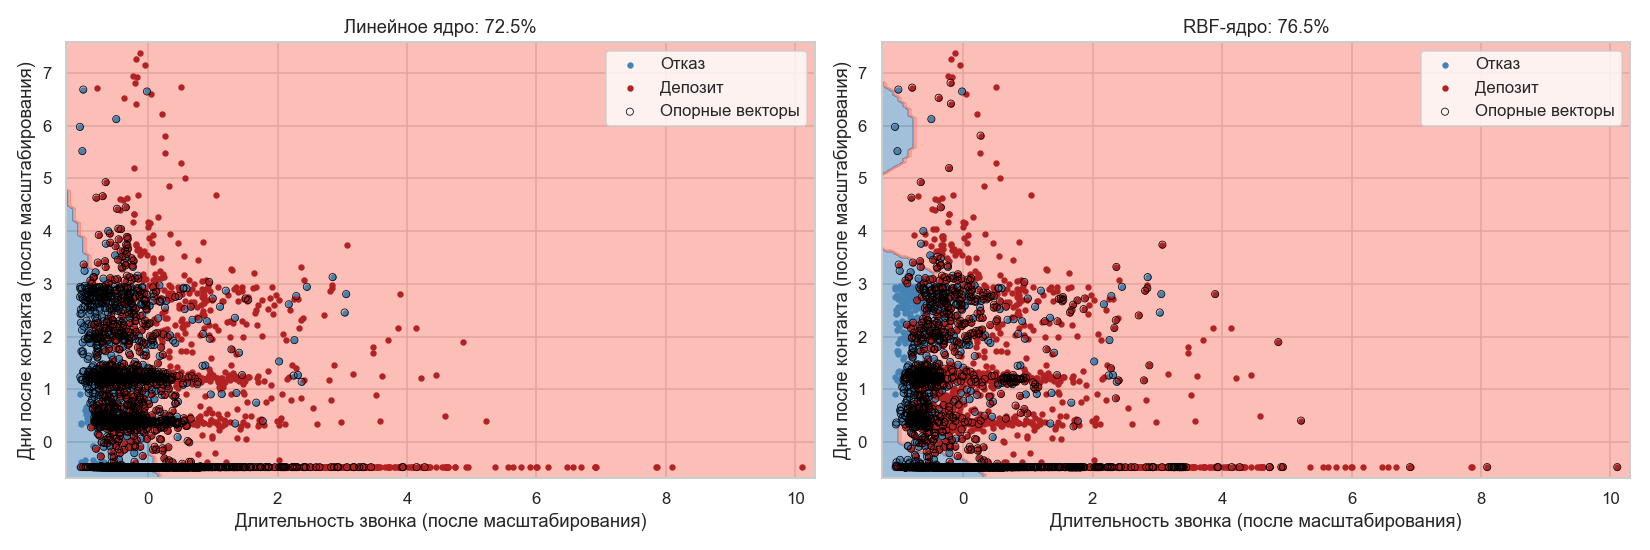

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

def plot_decision_boundary(model, ax, title):
    X_set, y_set = X_train_scaled, y_train
    X1, X2 = np.meshgrid(
        np.linspace(X_set[:, 0].min() - 0.2, X_set[:, 0].max() + 0.2, 150),
        np.linspace(X_set[:, 1].min() - 0.2, X_set[:, 1].max() + 0.2, 150)
    )
    classes = model.predict(np.c_[X1.ravel(), X2.ravel()]).reshape(X1.shape)
    ax.contourf(X1, X2, classes, alpha=0.5, cmap=ListedColormap(["steelblue", "salmon"]))
    for i, label in enumerate(["Отказ", "Депозит"]):
        ax.scatter(X_set[y_set == i, 0], X_set[y_set == i, 1],
                   color=["steelblue", "firebrick"][i], s=10, label=label)
    ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
               s=22, linewidth=0.5, facecolors="none", edgecolors="black",
               label="Опорные векторы")
    ax.set_title(title)
    ax.set_xlabel("Длительность звонка (после масштабирования)")
    ax.set_ylabel("Дни после контакта (после масштабирования)")
    ax.legend()

plot_decision_boundary(svm_linear, axes[0], f"Линейное ядро: {acc_lin:.1%}")
plot_decision_boundary(svm_rbf, axes[1], f"RBF-ядро: {acc_rbf:.1%}")
plt.tight_layout()
plt.show()

На первом графике классы разделены прямой линией, на втором — изогнутой. Опорные векторы выделены чёрными кольцами